# 02 · LMS step size and number of taps

The paper uses LMS with "default parameters in MATLAB" (`dsp.LMSFilter`: step size 0.1, 32 taps).
On the MIT-BIH / NSTDB signals that setting diverges, so the step size and number of taps are chosen here instead.
**One setting** is then used for every LMS filter in every method and experiment, as in the paper, and for **both EMD
implementations**, so the EMD is the only difference between the two sets of results.

**Only settings that converge are used.** The LMS weight error is multiplied by $I - \mu\,u(n)u(n)^T$ at every sample,
which is non-expansive only while $\mu\,\|u(n)\|^2 < 2$. The NSTDB references are strongly non-stationary
(the BW record has bursts about 10× its RMS), so this must hold for the **peak** tap-vector energy, not the average power:

$$\mu < \mu_{\max}(L) = \frac{2}{\max_n \|u(n)\|^2}$$

Every LMS filter input is a reference noise (or the sum of them for PDAF), so $\mu_{\max}$ is computed from the
references alone, for every case of every stage, **before** anything is filtered. Candidate settings at or above
the smallest limit are dropped, and `LMS_filter` refuses to run them. The sweep runs only the remaining settings.

Sweep: the paper's records (Fig. 8 records for BW+PLI with EMD, Fig. 10 records for the four methods) at every SNRin
the paper uses, with both EMDs (PDAF and SDAF don't use EMD and are run once).

**Chosen setting: stable, not best.** The paper selects LMS because it has *"a better and more stable performance at
different SNRinput"* (Sec. IV-A). The step size and taps are chosen the same way: the setting with the highest
**worst-case** SNRimp over all records, SNRin levels, methods and both EMDs (ties broken by the mean).

In [9]:
from pathlib import Path
import sys, json

project_root = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from src.claims import EMDS, EMD_LABEL, PAPER_IMFS
RESULTS = project_root / "results"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
METHOD_COLORS = {"PEAF": "#1f3b73", "SEAF": "#9aa83a", "PDAF": "#d62728", "SDAF": "#3cb9a0"}
EMD_COLORS = {"matlab": "tab:orange", "pyemd": "tab:purple"}


def show_check(title, result):
    """Print one claim check from src.claims: PASS / PARTLY / FAIL and our numbers."""
    mark = {"Yes": "PASS", "Partly": "PARTLY", "No": "FAIL"}.get(result["verdict"], result["verdict"])
    print(f"[{mark:>6}] {title}\n         {result['ours']}")

## Stability limit per number of taps (over every case of every stage)

In [10]:
limits = pd.read_csv(RESULTS / "lms_stability.csv")
worst = limits.loc[limits.groupby("taps").mu_limit.idxmin()].set_index("taps")
worst = worst.rename(columns={"mu_limit": "mu_max (smallest)", "input": "limiting input"})
worst[["mu_max (smallest)", "limiting input", "record", "SNRin_dB", "noises"]]

,mu_max (smallest),limiting input,record,SNRin_dB,noises
taps,,,,,
8,0.005945,sum,116,-5,bw+em+ma+pli
16,0.003317,sum,116,-5,bw+em+ma+pli
32,0.001998,sum,116,-5,bw+em+ma+pli
64,0.001023,sum,116,-5,bw+em+ma+pli


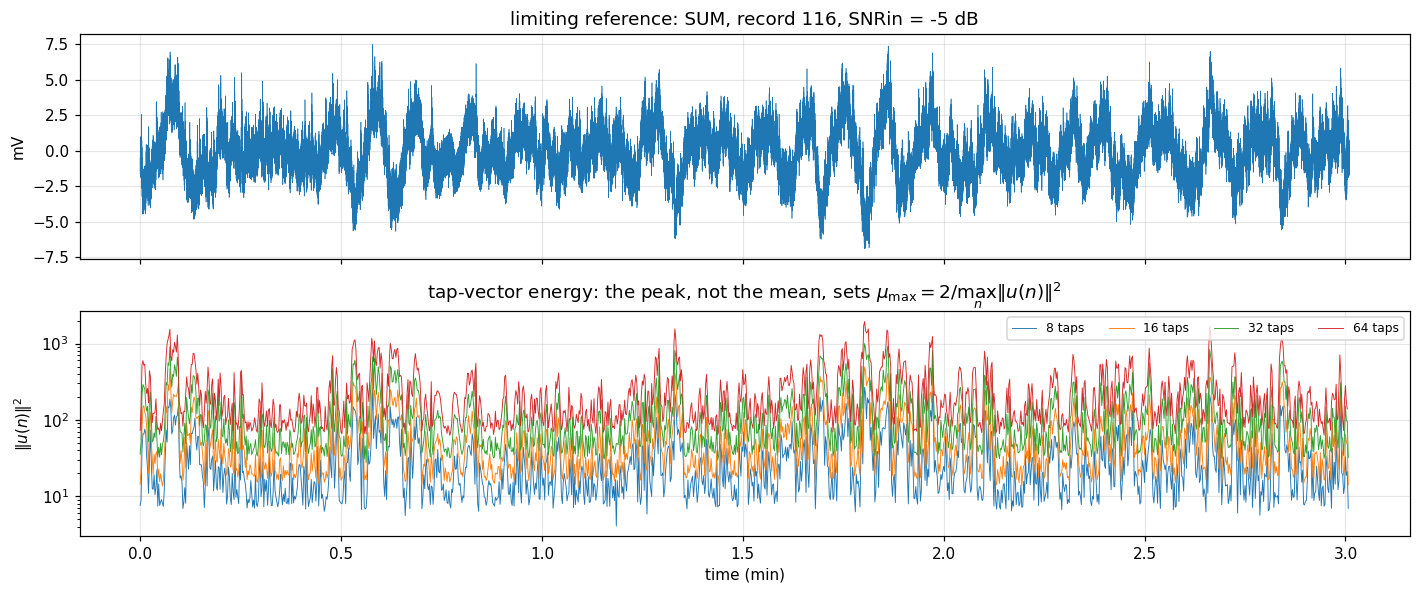

mean power 4.039 mV^2, peak |x| 7.48 mV, RMS 2.01 mV
MATLAB default mu = 0.1 with 32 taps is 50x the limit


In [11]:
from src.data_load import make_noisy_ecg
from src.adaptive_filters import lms_step_limit

w = worst.iloc[0]
case = make_noisy_ecg(int(w.record), tuple(n for n in w.noises.split("+") if n != "pli"), "pli" in w.noises, w.SNRin_dB)
x = case["references"][w["limiting input"]] if w["limiting input"] != "sum" else sum(case["references"].values())
fs = case["fs"]; t = np.arange(len(x)) / fs / 60
fig, axes = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True)
axes[0].plot(t, x, lw=0.4); axes[0].set_ylabel("mV")
axes[0].set_title(f"limiting reference: {w['limiting input'].upper()}, record {int(w.record)}, SNRin = {w.SNRin_dB} dB")
for L in sorted(limits.taps.unique()):
    e = np.convolve(x**2, np.ones(L), "valid")
    axes[1].semilogy(t[: len(e)][::50], e[::50], lw=0.6, label=f"{L} taps")
axes[1].set_ylabel(r"$\|u(n)\|^2$"); axes[1].set_xlabel("time (min)"); axes[1].legend(fontsize=8, ncol=4)
axes[1].set_title(r"tap-vector energy: the peak, not the mean, sets $\mu_{\max} = 2 / \max_n \|u(n)\|^2$")
plt.tight_layout(); plt.show()
print(f"mean power {np.mean(x**2):.3f} mV^2, peak |x| {np.abs(x).max():.2f} mV, RMS {np.sqrt(np.mean(x**2)):.2f} mV")
print("MATLAB default mu = 0.1 with 32 taps is", f"{0.1 / lms_step_limit(x, 32):.0f}x the limit")

In [12]:
sweep = pd.read_csv(RESULTS / "lms_sweep.csv")
setting = json.loads((RESULTS / "lms_setting.json").read_text())
print("chosen setting:", setting)
SHORT = {"matlab": "MATLAB EMD", "pyemd": "PyEMD", "none": ""}
sweep["label"] = [m if e == "none" else f"{m} ({SHORT[e]})" for m, e in zip(sweep.method, sweep.emd)]
MUS = sorted(sweep.mu.unique(), reverse=True); TAPS = sorted(sweep.taps.unique())
assert np.isfinite(sweep.SNRimp_dB).all(), "every swept setting converges"
for (mu, L), _ in sweep.groupby(["mu", "taps"]):
    assert mu < worst.loc[L, "mu_max (smallest)"]
assert set(sweep.emd) == {"matlab", "pyemd", "none"}
print(f"{sweep.groupby(['mu', 'taps']).ngroups} settings swept, all below the stability limit; "
      f"all {len(sweep)} runs finite (min SNRimp {sweep.SNRimp_dB.min():.2f} dB)")

def grid(df, agg="mean"):
    return df.groupby(["mu", "taps"]).SNRimp_dB.agg(agg).unstack().reindex(index=MUS, columns=TAPS)

def heat(ax, mean, title):
    im = ax.imshow(mean.values, cmap="viridis", aspect="auto")
    for i, mu in enumerate(MUS):
        for j, L in enumerate(TAPS):
            if np.isfinite(mean.loc[mu, L]):
                ax.text(j, i, f"{mean.loc[mu, L]:.1f}", ha="center", va="center", fontsize=7,
                        color="w" if mean.loc[mu, L] < np.nanmax(mean.values) - 3 else "k")
    ax.set_xticks(range(len(TAPS)), TAPS); ax.set_yticks(range(len(MUS)), [f"{m:g}" for m in MUS])
    ax.set_xlabel("taps"); ax.set_ylabel("step size μ"); ax.set_title(title, fontsize=9)
    ax.add_patch(plt.Rectangle((TAPS.index(setting["taps"]) - .5, MUS.index(setting["mu"]) - .5), 1, 1,
                               fill=False, ec="orange", lw=2.5, ls="--"))
    ax.grid(False)
    return im

chosen setting: {'mu': 0.001, 'taps': 8, 'criterion': 'max worst-case SNRimp over all sweep runs (records x SNRin x methods x EMDs)', 'worst_SNRimp_dB': 0.922, 'mean_SNRimp_dB': 6.51, 'std_SNRimp_dB': 3.799}
28 settings swept, all below the stability limit; all 14504 runs finite (min SNRimp -4.57 dB)


## Worst-case and mean SNRimp over all runs (orange dashed: chosen; blank: above the stability limit, not run)

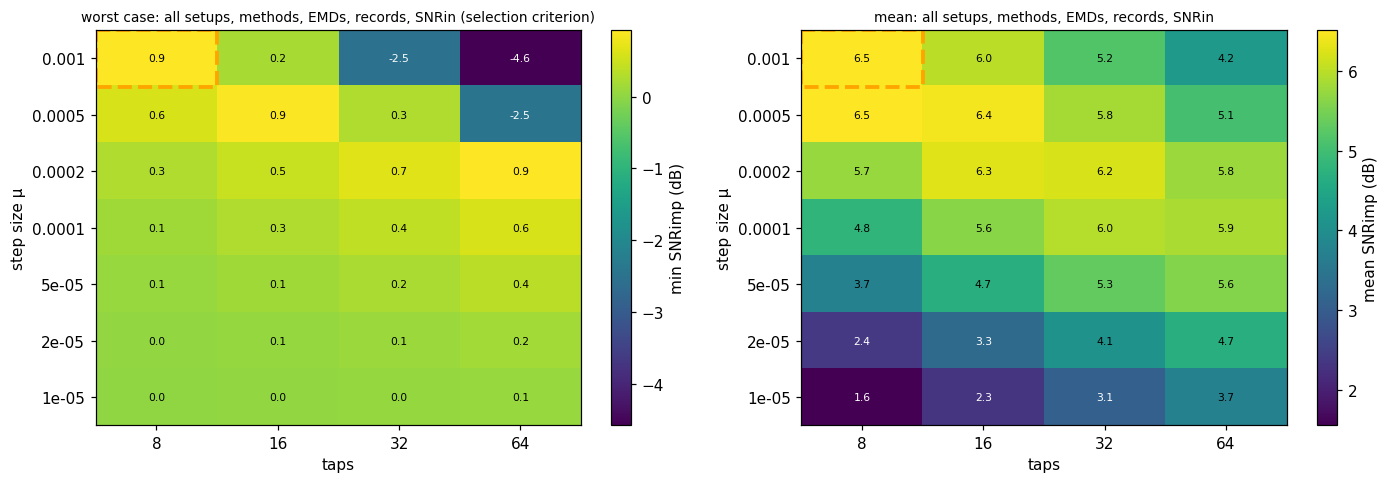

chosen (max worst case): {'min': 0.92, 'mean': 6.51, 'std': 3.8}
best mean (not chosen):  (np.float64(0.001), np.int64(8)) {'min': 0.92, 'mean': 6.51, 'std': 3.8}


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plt.colorbar(heat(axes[0], grid(sweep, "min"), "worst case: all setups, methods, EMDs, records, SNRin (selection criterion)"),
             ax=axes[0], label="min SNRimp (dB)")
plt.colorbar(heat(axes[1], grid(sweep), "mean: all setups, methods, EMDs, records, SNRin"), ax=axes[1], label="mean SNRimp (dB)")
plt.tight_layout(); plt.show()
stats = sweep.groupby(["mu", "taps"]).SNRimp_dB.agg(["min", "mean", "std"])
chosen = stats["min"].round(9).idxmax()
assert (setting["mu"], setting["taps"]) == max(stats.index, key=lambda k: (stats.loc[k, "min"], stats.loc[k, "mean"]))
print("chosen (max worst case):", stats.loc[(setting["mu"], setting["taps"])].round(2).to_dict())
print("best mean (not chosen): ", stats["mean"].idxmax(), stats.loc[stats["mean"].idxmax()].round(2).to_dict())

## Would each EMD alone pick a different setting?

The same criterion applied to the runs of one EMD only (plus the direct methods). If both pick the same setting,
sharing it costs neither EMD anything.

In [14]:
rows = {}
for e in EMDS:
    s = sweep[sweep.emd.isin([e, "none"])].groupby(["mu", "taps"]).SNRimp_dB.agg(["min", "mean"])
    best = max(s.index, key=lambda k: tuple(s.loc[k]))
    rows[EMD_LABEL[e]] = {"own choice (mu, taps)": best, "worst at own choice": s.loc[best, "min"],
                          "worst at shared setting": s.loc[(setting["mu"], setting["taps"]), "min"],
                          "mean at shared setting": s.loc[(setting["mu"], setting["taps"]), "mean"]}
pd.DataFrame(rows).T

,"own choice (mu, taps)",worst at own choice,worst at shared setting,mean at shared setting
MATLAB-default EMD,"(0.0002, 32)",3.27404,3.11269,8.760269
PyEMD,"(0.001, 8)",0.922241,0.922241,5.199164


## Per method and SNRin

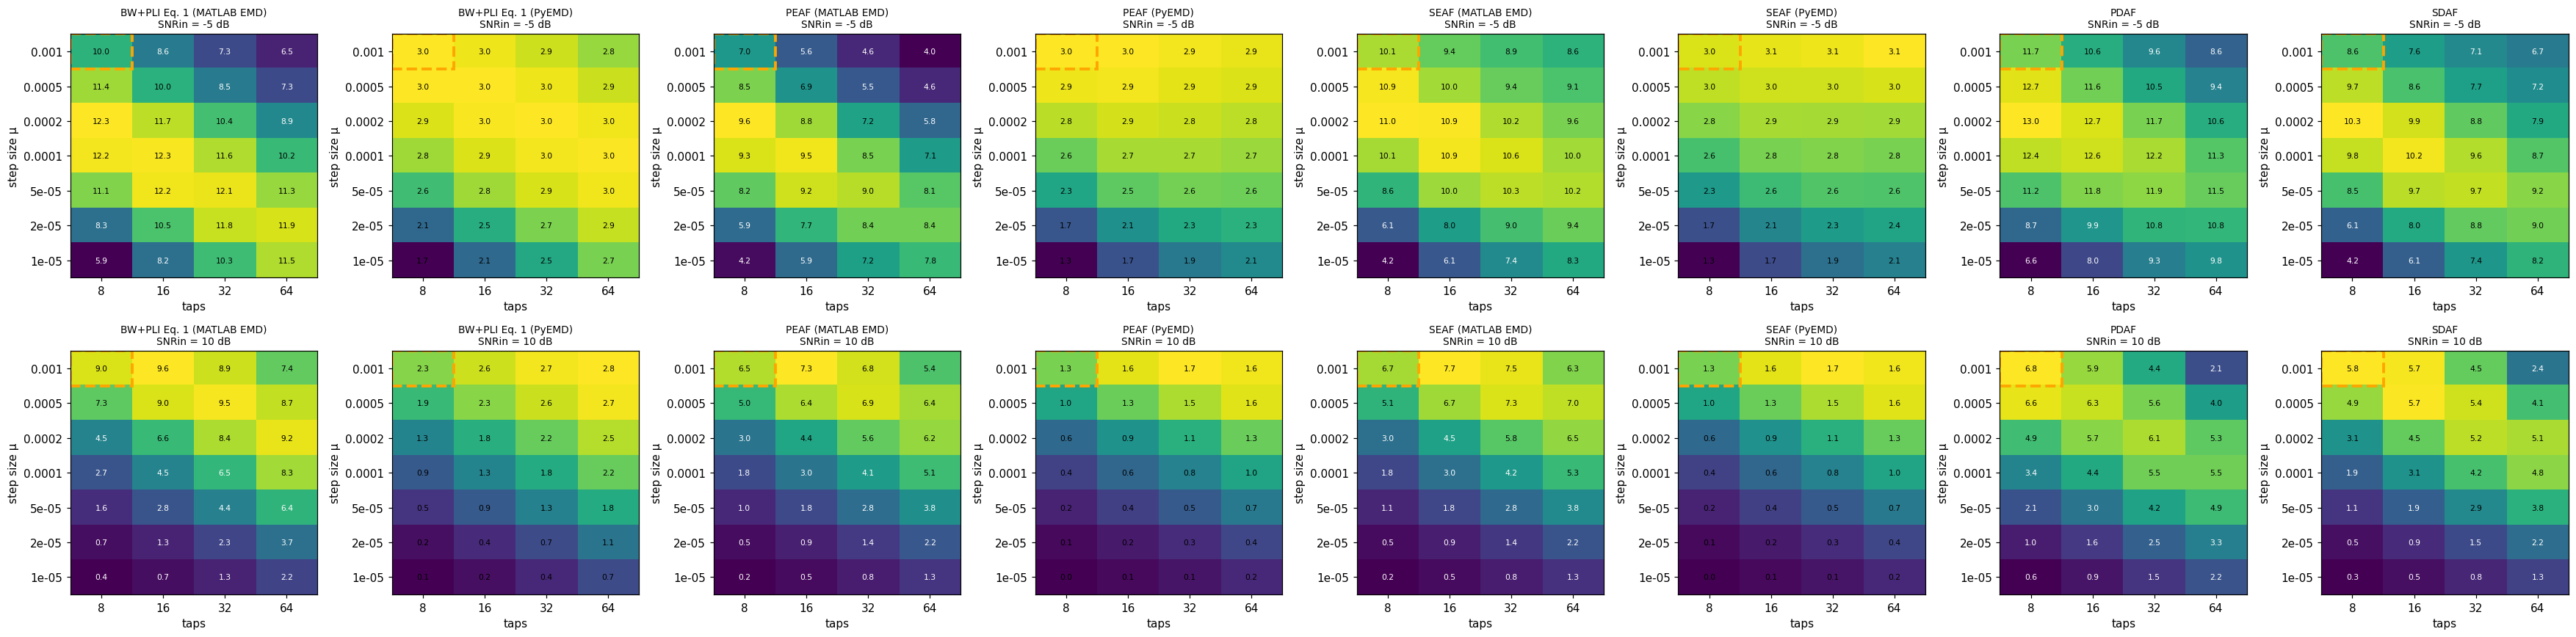

In [15]:
labels = ["EMD+LMS (MATLAB EMD)", "EMD+LMS (PyEMD)", "PEAF (MATLAB EMD)", "PEAF (PyEMD)",
          "SEAF (MATLAB EMD)", "SEAF (PyEMD)", "PDAF", "SDAF"]
fig, axes = plt.subplots(2, len(labels), figsize=(4 * len(labels), 8))
for col, lab in enumerate(labels):
    for row, snr in enumerate([-5, 10]):
        name = lab.replace("EMD+LMS", "BW+PLI Eq. 1")
        heat(axes[row, col], grid(sweep[(sweep.label == lab) & (sweep.SNRin_dB == snr)]), f"{name}\nSNRin = {snr} dB")
plt.tight_layout(); plt.show()

## SNRimp vs step size (taps fixed at the chosen value)

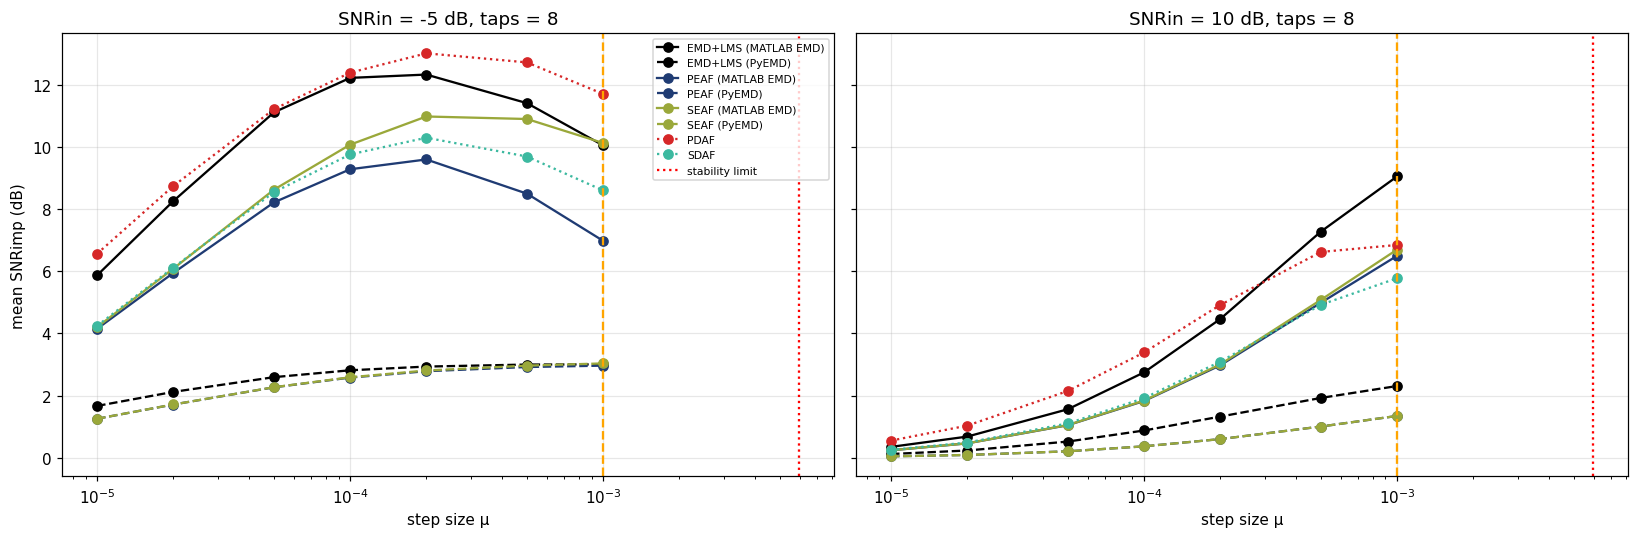

In [16]:
styles = {"MATLAB EMD": "-", "PyEMD": "--"}
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, snr in zip(axes, [-5, 10]):
    d = sweep[(sweep.SNRin_dB == snr) & (sweep.taps == setting["taps"])]
    for lab in labels:
        v = d[d.label == lab].groupby("mu").SNRimp_dB.mean()
        m = lab.split()[0]
        ls = next((s for k, s in styles.items() if k in lab), ":")
        ax.semilogx(v.index, v.values, marker="o", ls=ls, label=lab, color=METHOD_COLORS.get(m, "k"))
    ax.axvline(setting["mu"], color="orange", ls="--")
    ax.axvline(worst.loc[setting["taps"], "mu_max (smallest)"], color="red", ls=":", label="stability limit")
    ax.set_xlabel("step size μ"); ax.set_title(f"SNRin = {snr} dB, taps = {setting['taps']}")
axes[0].set_ylabel("mean SNRimp (dB)"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## Table: worst-case / mean SNRimp per setting (blank: above the stability limit, not run)

In [17]:
display(grid(sweep, "min").round(2)); grid(sweep).round(2)

taps,8,16,32,64
mu,,,,
0.00100,0.92,0.21,-2.50,-4.57
0.00050,0.58,0.88,0.26,-2.45
0.00020,0.27,0.47,0.66,0.91
0.00010,0.14,0.26,0.39,0.60
0.00005,0.07,0.14,0.22,0.35
0.00002,0.03,0.06,0.09,0.15
0.00001,0.01,0.03,0.05,0.08


taps,8,16,32,64
mu,,,,
0.00100,6.51,6.01,5.16,4.22
0.00050,6.49,6.42,5.85,5.05
0.00020,5.75,6.26,6.21,5.77
0.00010,4.81,5.62,5.96,5.89
0.00005,3.73,4.69,5.32,5.58
0.00002,2.38,3.28,4.09,4.66
0.00001,1.56,2.29,3.08,3.74
